In [9]:
# === LOAD: locate repo and load `sessions` with all_data_df ===
import sys, pickle
from pathlib import Path
import pandas as pd

# Try to discover the repo root from the current notebook location
start = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd().resolve()
for p in (start, *start.parents):
    if p.name == "syllable_generation":
        REPO_ROOT = p
        break
else:
    # fallback to your known absolute path
    REPO_ROOT = Path("/home/fsp585/Desktop/FiberphotometryCode/syllable_generation")

# Make package importable (optional, but matches your pattern)
PKG_PARENT = REPO_ROOT.parent
for pth in (str(PKG_PARENT), str(REPO_ROOT)):
    if pth not in sys.path:
        sys.path.insert(0, pth)

# Optional sanity check for the package
try:
    import importlib; importlib.import_module("syllable_generation")
except Exception as e:
    print("Warning: could not import `syllable_generation` (not fatal):", e)

# Default PKL path from your earlier snippet
PKL = REPO_ROOT / "loaders" / "jonathan_ifdn_sessions_w_all_data.pkl"

# Fallback: search for a suitable PKL if the default is missing
if not PKL.exists():
    loaders_dir = REPO_ROOT / "loaders"
    candidates = list(loaders_dir.glob("*sessions*all_data*.pkl")) + list(loaders_dir.glob("*.pkl"))
    if not candidates:
        raise FileNotFoundError(f"Could not find a sessions pickle under {loaders_dir}")
    # pick the most recent
    PKL = max(candidates, key=lambda p: p.stat().st_mtime)
    print(f"Using fallback pickle: {PKL}")

with PKL.open("rb") as f:
    sessions = pickle.load(f)

print(f"Loaded {len(sessions)} sessions from {PKL}")

# Keep only sessions that actually have non-empty all_data_df
sessions = [
    s for s in sessions
    if hasattr(s, "all_data_df") and isinstance(s.all_data_df, pd.DataFrame) and not s.all_data_df.empty
]
print(f"Usable sessions with all_data_df: {len(sessions)}")

# Quick peek
if sessions:
    s0 = sessions[0]
    sid  = getattr(s0, "session_id", "<no id>")
    geno = (getattr(s0, "metadata", {}) or {}).get("genotype", "UNK")
    print(f"Example session: {sid} | genotype={geno}")
    display(s0.all_data_df.head())
else:
    raise RuntimeError("No usable sessions found; check your pickle or preprocessing.")

Using fallback pickle: /home/fsp585/Desktop/FiberphotometryCode/syllable_generation/loaders/asdasdasd copy.pkl
Loaded 19 sessions from /home/fsp585/Desktop/FiberphotometryCode/syllable_generation/loaders/asdasdasd copy.pkl
Usable sessions with all_data_df: 19
Example session: 2024-12-13T12_20_06_bottom_left | genotype=WT


,name,centroid_x,centroid_y,heading,angular_velocity,velocity_px_s,syllable,frame_index,group,onset,...,signal_0_zscore_datta,signal_1_dff,signal_1_zscore,signal_1_zscore_datta,signal_2_dff,signal_2_zscore,signal_2_zscore_datta,signal_3_dff,signal_3_zscore,signal_3_zscore_datta
0,Arena1234_CenterTopCamVid_2024-12-13T12_20_06_...,167.051823,199.522437,-1.122018,0.000000,0.000000,56,69517,WT,True,...,0.284346,-0.456758,-0.635931,-0.340642,-0.342478,-0.795487,-1.066838,-0.565258,-0.636459,-0.953344
1,Arena1234_CenterTopCamVid_2024-12-13T12_20_06_...,166.903142,199.062367,-1.122018,0.012100,14.504940,56,69518,WT,False,...,0.458511,-0.457280,-0.642150,-0.387259,-0.341230,-0.789986,-1.007153,-0.565216,-0.636034,-0.862807
2,Arena1234_CenterTopCamVid_2024-12-13T12_20_06_...,167.223306,199.104034,-1.122018,0.027302,9.685929,56,69519,WT,False,...,0.632677,-0.457802,-0.648369,-0.433876,-0.339982,-0.784485,-0.947469,-0.565174,-0.635609,-0.772271
3,Arena1234_CenterTopCamVid_2024-12-13T12_20_06_...,167.995061,199.575542,-1.136146,0.046672,27.131755,56,69520,WT,False,...,0.806842,-0.458323,-0.654588,-0.480492,-0.338734,-0.778983,-0.887785,-0.565133,-0.635184,-0.681734
4,Arena1234_CenterTopCamVid_2024-12-13T12_20_06_...,168.522242,201.069801,-1.122018,0.068494,47.535846,56,69521,WT,False,...,1.072744,-0.457493,-0.644689,-0.433324,-0.338548,-0.778165,-0.890066,-0.563833,-0.621913,-0.537591


In [10]:
sessions[0].all_data_df.columns

Index(['name', 'centroid_x', 'centroid_y', 'heading', 'angular_velocity',
       'velocity_px_s', 'syllable', 'frame_index', 'group', 'onset',
       'SystemTimestamp', 'signal_0', 'signal_1', 'signal_2', 'signal_3',
       'signal_0_dff', 'signal_0_zscore', 'signal_0_zscore_datta',
       'signal_1_dff', 'signal_1_zscore', 'signal_1_zscore_datta',
       'signal_2_dff', 'signal_2_zscore', 'signal_2_zscore_datta',
       'signal_3_dff', 'signal_3_zscore', 'signal_3_zscore_datta'],
      dtype='object')

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def classify_nans(df):
    """
    Classify each row into one of three categories:
    1. VALID: Timestamp & Signal exist.
    2. EXCLUSION: Timestamp exists, but Signal is NaN (likely manual exclusion).
    3. ALIGNMENT_GAP: Timestamp is NaN (cannot bin/use).
    """
    # Define what constitutes "Signal" columns (using datta z-score as proxy)
    sig_cols = [c for c in df.columns if "zscore_datta" in c]
    if not sig_cols:
        return None
    
    # We check the first available signal column (usually they are all NaN together if excluded)
    target_sig = sig_cols[0]
    
    # Boolean masks
    has_ts = df["SystemTimestamp"].notna()
    has_sig = df[target_sig].notna()
    
    # Logic
    res = pd.Series("UNKNOWN", index=df.index)
    res[has_ts & has_sig] = "VALID"
    res[has_ts & ~has_sig] = "EXCLUSION"  # Valid time, no signal
    res[~has_ts] = "ALIGNMENT_GAP"       # No time (usually at the end)
    
    return res

def analyze_gap_location(df):
    """
    Check if ALIGNMENT_GAPS are at the Start, Middle, or End.
    Returns: (n_start, n_middle, n_end)
    """
    status = classify_nans(df)
    if status is None: return (0,0,0)
    
    is_gap = (status == "ALIGNMENT_GAP")
    if not is_gap.any():
        return (0, 0, 0)
    
    gap_indices = np.flatnonzero(is_gap)
    n_total = len(df)
    
    # "End" is defined as a contiguous block touching the last index
    n_end = 0
    if gap_indices[-1] == n_total - 1:
        # Walk backwards
        curr = n_total - 1
        while curr >= 0 and is_gap.iloc[curr]:
            n_end += 1
            curr -= 1

    # "Start" is contiguous block touching index 0
    n_start = 0
    if gap_indices[0] == 0:
        curr = 0
        while curr < n_total and is_gap.iloc[curr]:
            n_start += 1
            curr += 1
            
    # "Middle" is everything else
    n_mid = is_gap.sum() - n_start - n_end
    
    return (n_start, n_mid, n_end)

In [13]:
stats_rows = []

for s in sessions:
    sid = s.session_id
    df = s.all_data_df
    
    status = classify_nans(df)
    if status is None:
        print(f"Skipping {sid}: No zscore_datta columns found.")
        continue

    # Counts
    counts = status.value_counts()
    n_valid = counts.get("VALID", 0)
    n_excl  = counts.get("EXCLUSION", 0)
    n_align = counts.get("ALIGNMENT_GAP", 0)
    
    # Location Analysis
    gap_start, gap_mid, gap_end = analyze_gap_location(df)
    
    stats_rows.append({
        "session_id": sid,
        "total_frames": len(df),
        "valid_frames": n_valid,
        "manual_exclusions": n_excl,
        "alignment_gaps": n_align,
        "gap_start": gap_start,
        "gap_mid": gap_mid,
        "gap_end": gap_end,
        "pct_gap": (n_align / len(df)) * 100
    })

stats_df = pd.DataFrame(stats_rows)

print("=== GLOBAL SUMMARY ===")
print(f"Total Frames Processed: {stats_df['total_frames'].sum():,}")
print(f"Total Manual Exclusions: {stats_df['manual_exclusions'].sum():,} ({stats_df['manual_exclusions'].sum()/stats_df['total_frames'].sum():.1%})")
print(f"Total Alignment Gaps:    {stats_df['alignment_gaps'].sum():,}    ({stats_df['alignment_gaps'].sum()/stats_df['total_frames'].sum():.1%})")

# Check where the alignment gaps usually are
n_gap_total = stats_df["alignment_gaps"].sum()
if n_gap_total > 0:
    print(f"\nLocation of Alignment Gaps (Missing Timestamps):")
    print(f"  Start:  {stats_df['gap_start'].sum() / n_gap_total:.1%} (Video started before DAQ)")
    print(f"  Middle: {stats_df['gap_mid'].sum()   / n_gap_total:.1%} (Dropped Packets / Interpolation Fail)")
    print(f"  End:    {stats_df['gap_end'].sum()   / n_gap_total:.1%} (Video ran longer than DAQ)")
else:
    print("No alignment gaps found!")

display(stats_df.sort_values("alignment_gaps", ascending=False).head(100))

=== GLOBAL SUMMARY ===
Total Frames Processed: 4,114,935
Total Manual Exclusions: 409,891 (10.0%)
Total Alignment Gaps:    23,682    (0.6%)

Location of Alignment Gaps (Missing Timestamps):
  Start:  0.0% (Video started before DAQ)
  Middle: 100.0% (Dropped Packets / Interpolation Fail)
  End:    0.0% (Video ran longer than DAQ)


,session_id,total_frames,valid_frames,manual_exclusions,alignment_gaps,gap_start,gap_mid,gap_end,pct_gap
16,2024-12-16T15_14_26_bottom_left,221143,207442,1852,11849,0,11849,0,5.358071
17,2024-12-16T15_14_26_top_left,220051,205239,2996,11816,0,11816,0,5.369664
0,2024-12-13T12_20_06_bottom_left,221392,221390,0,2,0,2,0,0.000903
7,2024-12-13T14_50_39_top_left,221039,221037,0,2,0,2,0,0.000905
10,2024-12-16T11_27_19_top_left,251911,251909,0,2,0,2,0,0.000794
1,2024-12-13T12_20_06_bottom_right,217043,217041,0,2,0,2,0,0.000921
8,2024-12-16T11_27_19_bottom_left,219419,219417,0,2,0,2,0,0.000911
9,2024-12-16T11_27_19_bottom_right,217678,217676,0,2,0,2,0,0.000919
6,2024-12-13T14_50_39_bottom_right,218870,218868,0,2,0,2,0,0.000914
5,2024-12-13T14_50_39_bottom_left,218981,218979,0,2,0,2,0,0.000913


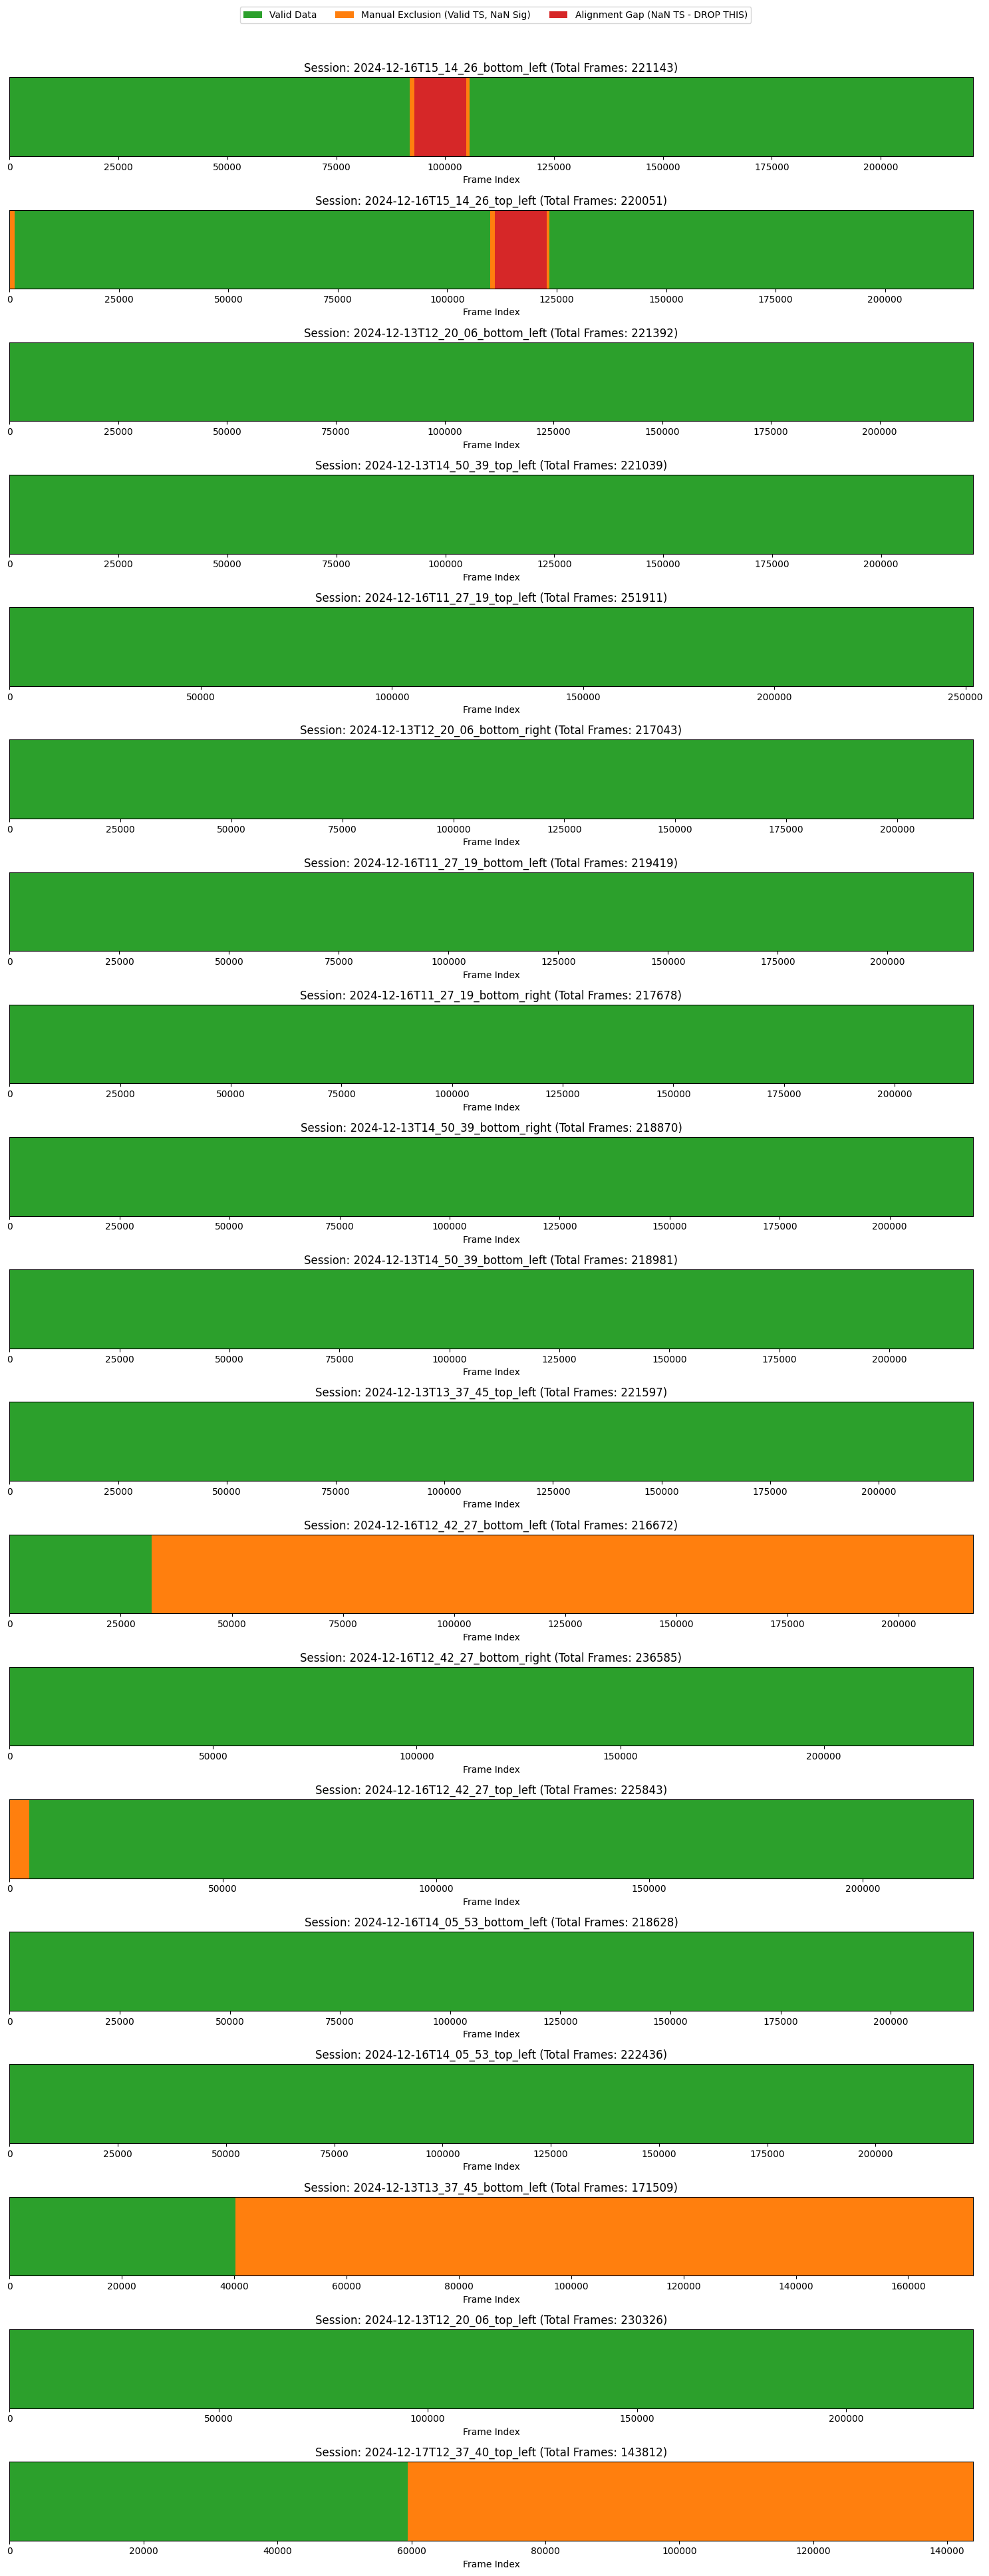

In [17]:
# Pick top 3 sessions with most alignment gaps (or just random ones if few gaps)
worst_sessions = stats_df.sort_values("alignment_gaps", ascending=False).head(20)["session_id"].tolist()

# Plotting
fig, axes = plt.subplots(len(worst_sessions), 1, figsize=(15, 2 * len(worst_sessions)), sharex=False)
if len(worst_sessions) == 1: axes = [axes]

category_map = {"VALID": 0, "EXCLUSION": 1, "ALIGNMENT_GAP": 2}
colors = ["#2ca02c", "#ff7f0e", "#d62728"] # Green (Good), Orange (Excl), Red (Gap)
cmap =  plt.matplotlib.colors.ListedColormap(colors)

for ax, sid in zip(axes, worst_sessions):
    s = next(s for s in sessions if s.session_id == sid)
    df = s.all_data_df
    status = classify_nans(df)
    
    # Convert to numeric for imshow
    numeric_status = status.map(category_map).values.reshape(1, -1)
    
    # Use imshow to create a "barcode"
    ax.imshow(numeric_status, aspect='auto', cmap=cmap, interpolation='nearest', vmin=0, vmax=2)
    ax.set_title(f"Session: {sid} (Total Frames: {len(df)})")
    ax.set_yticks([])
    ax.set_xlabel("Frame Index")

# Custom Legend
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor=colors[0], label='Valid Data'),
    Patch(facecolor=colors[1], label='Manual Exclusion (Valid TS, NaN Sig)'),
    Patch(facecolor=colors[2], label='Alignment Gap (NaN TS - DROP THIS)')
]
fig.legend(handles=legend_elements, loc='upper center', bbox_to_anchor=(0.5, 1.02), ncol=20)
plt.tight_layout()
plt.show()